<a href="https://colab.research.google.com/github/cristobalcresposandoval-lang/CSN/blob/main/Ejercicios_histogramas_boxplots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unsdsn/world-happiness")

print("Path to dataset files:", path)


### Cargar y Explorar los Datos
Vamos a listar los archivos descargados y cargar el dataset en un DataFrame de Pandas para analizar sus columnas y estructura general.

In [2]:
import os
import pandas as pd
import kagglehub

# Asegurar que la ruta esté definida
try:
    path
except NameError:
    print("La variable 'path' no estaba definida. Descargando o recuperando la ruta...")
    path = kagglehub.dataset_download("unsdsn/world-happiness")

print("Ruta del dataset:", path)

# Listar archivos en la ruta de descarga
files = os.listdir(path)
print("Archivos disponibles:", files)

# Encontrar el archivo CSV del dataset
csv_files = [f for f in files if f.endswith('.csv')]
print("Archivos CSV:", csv_files)

# Cargar el primer dataset encontrado para exploración
if csv_files:
    # Usamos 2019.csv o el último disponible que suele tener el formato requerido (Score, GDP per capita, etc.)
    # Busquemos si existe '2019.csv' explícitamente, de lo contrario usamos el último de la lista
    selected_file = '2019.csv' if '2019.csv' in csv_files else csv_files[-1]
    df_path = os.path.join(path, selected_file)
    df = pd.read_csv(df_path)
    print(f"\nDataset cargado con éxito desde: {selected_file}")
    display(df.head())
    print("\nInformación general del dataset:")
    df.info()
else:
    print("No se encontraron archivos CSV en la ruta.")

La variable 'path' no estaba definida. Descargando o recuperando la ruta...


100%|██████████| 36.8k/36.8k [00:00<00:00, 3.82MB/s]

Extracting files...
Ruta del dataset: /root/.cache/kagglehub/datasets/unsdsn/world-happiness/versions/2
Archivos disponibles: ['2018.csv', '2019.csv', '2017.csv', '2015.csv', '2016.csv']
Archivos CSV: ['2018.csv', '2019.csv', '2017.csv', '2015.csv', '2016.csv']

Dataset cargado con éxito desde: 2019.csv


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298



Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


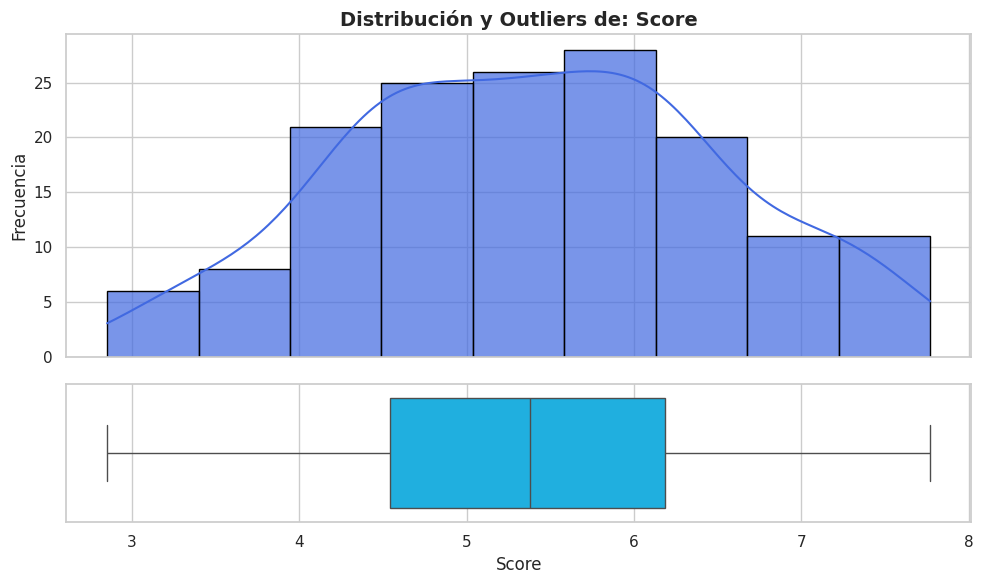

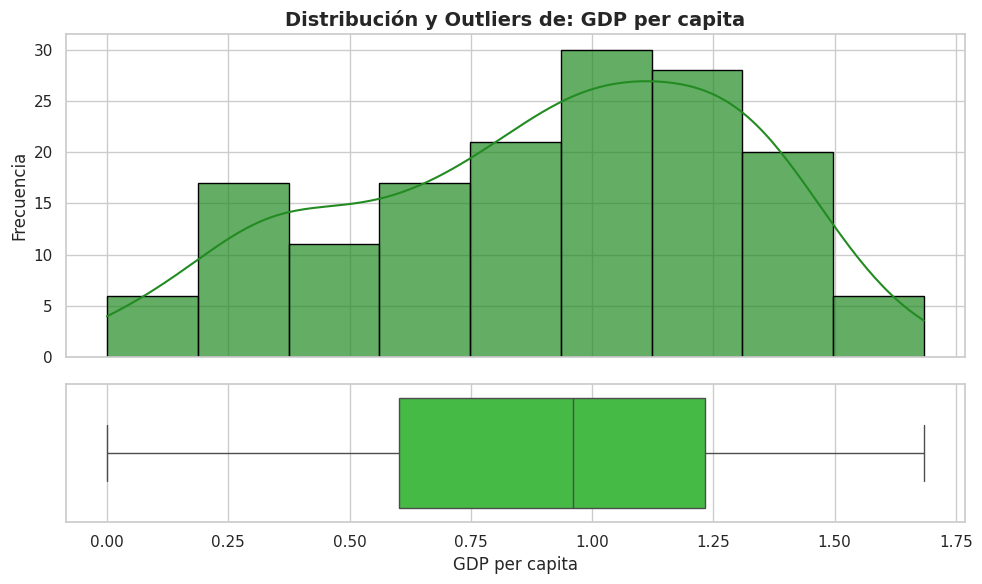

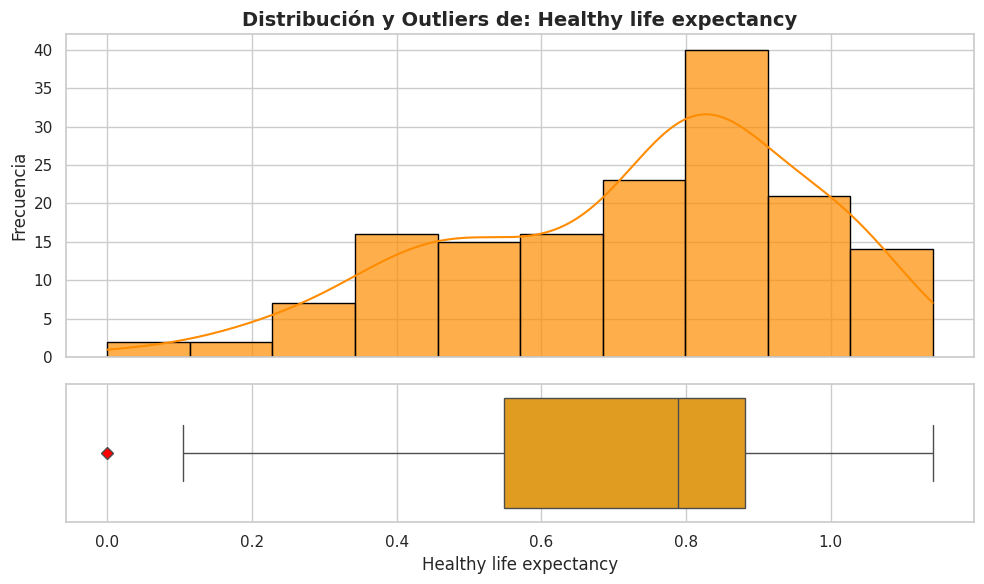

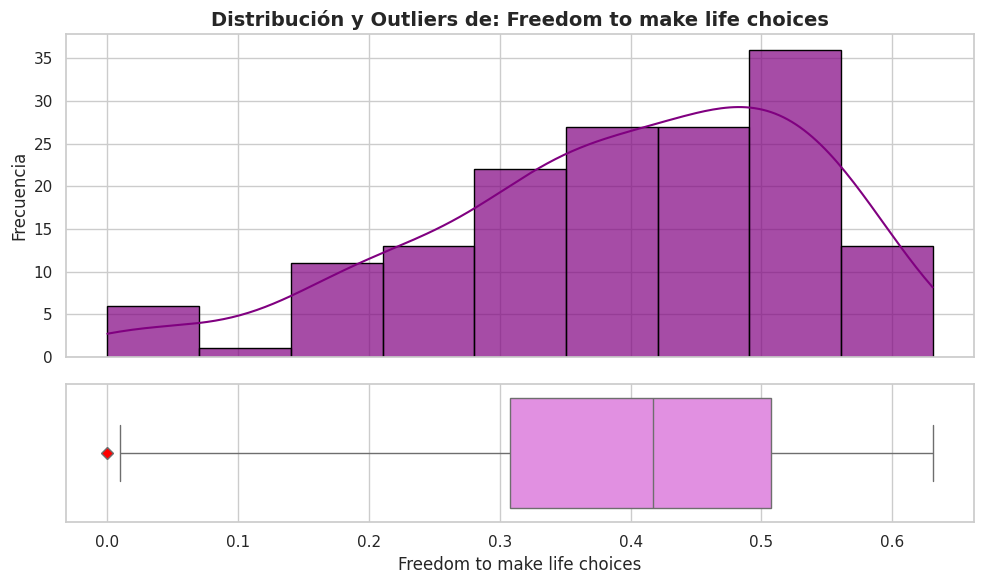

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo general de los gráficos
sns.set_theme(style="whitegrid")

# Variables a analizar
variables = [
    ('Score', 'royalblue', 'deepskyblue'),
    ('GDP per capita', 'forestgreen', 'limegreen'),
    ('Healthy life expectancy', 'darkorange', 'orange'),
    ('Freedom to make life choices', 'purple', 'violet')
]

for col_name, color_hist, color_box in variables:
    # Crear una figura con 2 subplots (Histograma arriba, Boxplot abajo)
    fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                           gridspec_kw={"height_ratios": (0.7, 0.3)})

    # 1. Histograma
    sns.histplot(data=df, x=col_name, ax=ax_hist, color=color_hist, kde=True, edgecolor="black", alpha=0.7)
    ax_hist.set_title(f'Distribución y Outliers de: {col_name}', fontsize=14, fontweight='bold')
    ax_hist.set_ylabel('Frecuencia')
    ax_hist.set_xlabel('')

    # 2. Boxplot
    sns.boxplot(data=df, x=col_name, ax=ax_box, color=color_box, flierprops=dict(markerfacecolor='red', marker='D'))
    ax_box.set_xlabel(col_name, fontsize=12)

    # Ajustar el diseño y mostrar
    plt.tight_layout()
    plt.show()
    print("\n" + "="*80 + "\n")